# 11. 고장 이벤트 경보와 임계값 분석

F1 임계값과 Event Recall/FAR 제약 임계값은 별도 내부 보정 장비에서만 정했습니다. FAR≤0.1/h는 실험용 사전 제약이며 전체 운영 오경보율을 의미하지 않습니다. 이미 확인한 4단계 평가 결과는 원인 진단에만 사용했고 새 임계값을 적용해 개선 성능으로 보고하지 않았습니다.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import pandas as pd
from IPython.display import display,Markdown,Image
from src.improvement_common import OUT,read_json,configs
pd.set_option("display.max_columns",30)
print("실행 Python:",sys.executable)
print("저장된 실제 실험 결과를 읽습니다. 이 Notebook은 모델을 재학습하지 않습니다.")
def show(name):display(Image(filename=str(OUT/"figures"/(name+".png"))))


실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
저장된 실제 실험 결과를 읽습니다. 이 Notebook은 모델을 재학습하지 않습니다.


,fault_code,rows,events,score_q50,score_q95,score_max,threshold,alarm_rows
0,f1,242,30,0.382094,0.571652,0.620401,0.652733,0
1,f2,71,11,0.490657,0.684552,0.684552,0.652733,24
2,f3,35,4,0.571652,0.574088,0.574088,0.652733,0


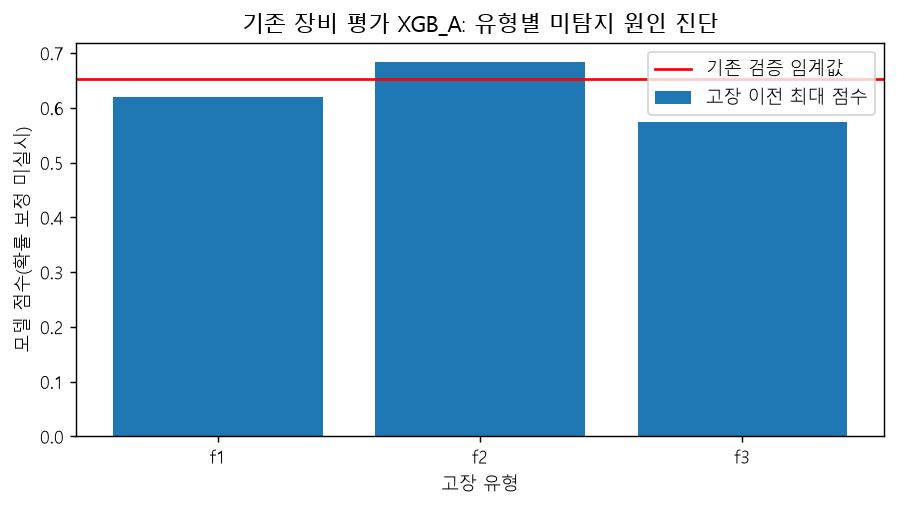

,threshold,precision,recall,f1,pr_auc_ap,event_recall,false_alarms_per_active_hour,lead_time_median_raw,unknown_episodes
0,0.000000,0.004809,1.000000,0.009571,0.011794,0.976744,4.875191,560.0,74212
1,0.100000,0.004809,1.000000,0.009571,0.011794,0.976744,4.875191,560.0,74212
2,0.250000,0.004809,1.000000,0.009571,0.011794,0.976744,4.875191,560.0,74212
3,0.470848,0.008338,0.484848,0.016393,0.011794,0.511628,1.046339,549.0,53608
4,0.500000,0.010529,0.327824,0.020403,0.011794,0.372093,0.939388,555.0,45588
5,0.596704,0.008086,0.159780,0.015393,0.011794,0.186047,0.602492,556.0,30333
6,0.640007,0.138889,0.027548,0.045977,0.011794,0.023256,0.007130,572.0,13261
7,0.652733,0.196078,0.027548,0.048309,0.011794,0.023256,0.005348,572.0,13149
8,0.679230,NaN,0.000000,0.000000,0.011794,0.000000,0.000000,NaN,7318
9,0.750000,NaN,0.000000,0.000000,0.011794,0.000000,0.000000,NaN,0


In [2]:
display(pd.DataFrame(read_json(OUT/"diagnostics.json")["old_tool_xgb_fault_scores"]))
show("old_fault_scores")
old=pd.DataFrame(read_json(OUT/"old_validation_threshold_grid.json"))
display(old[["threshold","precision","recall","f1","pr_auc_ap","event_recall","false_alarms_per_active_hour","lead_time_median_raw","unknown_episodes"]])

압력 저하 f1의 평가 양성 점수 최대 0.62040이 검증 임계값 0.65273보다 낮아 30건을 탐지하지 못했습니다. 이것은 임계값 미통과의 직접 증거이며 센서 전조 부재의 증거는 아닙니다. 임계값을 낮출 때 알려진 음성 경보와 미확인 구간 경보가 함께 늘 수 있습니다.

,fold,model,threshold,precision,recall,f1,pr_auc_ap,event_recall,false_alarms_per_active_hour,lead_time_median_raw,unknown_episodes
0,0,A,0.000000,0.011950,1.000000,0.023617,0.047714,1.000000,4.945773,550.0,38915
1,0,A,0.100000,0.012092,0.923913,0.023871,0.047714,0.945946,4.382749,550.0,37101
2,0,A,0.250000,0.025082,0.500000,0.047767,0.047714,0.621622,2.145376,394.0,22520
3,0,A,0.270614,0.025588,0.496377,0.048668,0.047714,0.594595,2.053379,395.0,21810
4,0,A,0.500000,0.056865,0.297101,0.095460,0.047714,0.459459,0.688140,298.0,19018
...,...,...,...,...,...,...,...,...,...,...,...
211,3,C_regularized,0.650554,0.000103,0.030303,0.000206,0.000732,0.250000,0.727193,132.0,7950
212,3,C_regularized,0.750000,NaN,0.000000,0.000000,0.000732,0.000000,0.000000,NaN,0
213,3,C_regularized,0.900000,NaN,0.000000,0.000000,0.000732,0.000000,0.000000,NaN,0
214,3,C_regularized,0.990000,NaN,0.000000,0.000000,0.000732,0.000000,0.000000,NaN,0


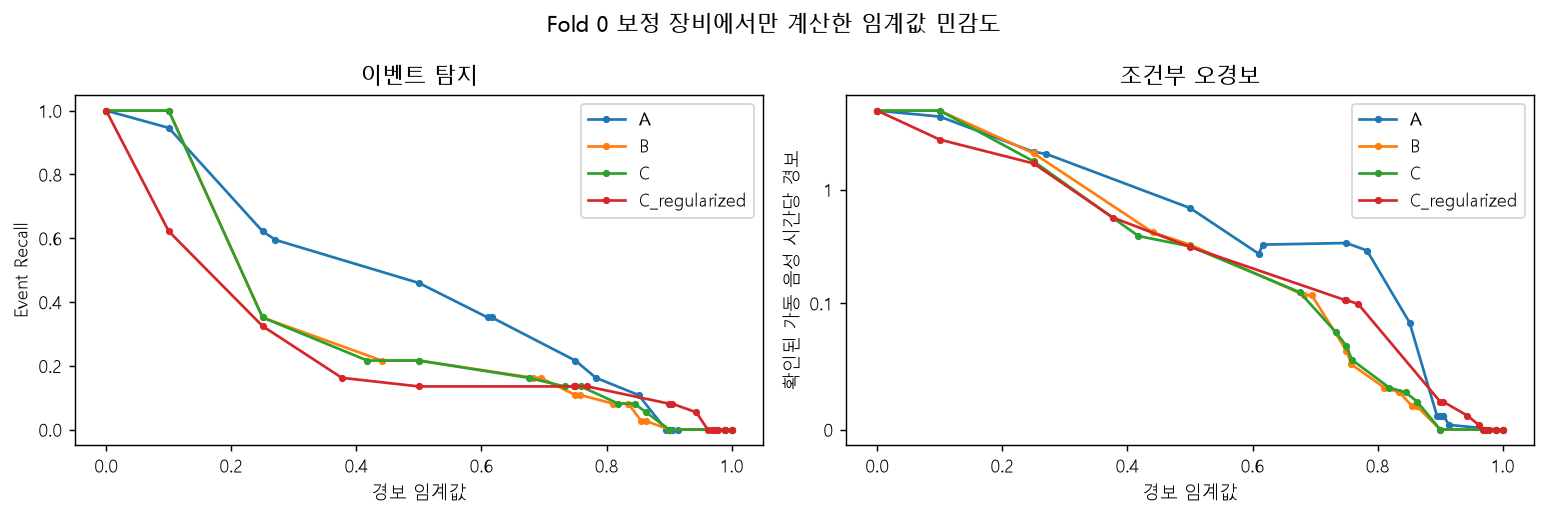

,fold,model,policy,threshold,eligible_events,detected_events,active_negative_hours,active_false_episodes,false_alarms_per_active_hour,unknown_episodes,unknown_rows,unknown_alarm_rows,lead_time_median_raw
0,0,A,f1,0.609952,17,6,392.251111,1333,3.398333,24687,226144,92486,499.0
1,0,A,event_far,0.851112,17,5,392.251111,1253,3.194382,18355,226144,65160,452.0
2,0,B,f1,0.694680,17,5,392.251111,275,0.701082,33680,226144,70817,120.0
3,0,B,event_far,0.758173,17,1,392.251111,161,0.410451,25471,226144,44607,72.0
4,0,C,f1,0.732879,17,3,392.251111,203,0.517526,27619,226144,48749,120.0
5,0,C,event_far,0.758886,17,1,392.251111,160,0.407902,25191,226144,43028,72.0
6,0,C_regularized,f1,0.747727,17,4,392.251111,1044,2.661560,34409,226144,78999,343.0
7,0,C_regularized,event_far,0.768922,17,4,392.251111,1073,2.735493,33715,226144,75544,343.0
8,1,A,f1,0.502270,95,68,3103.815556,7912,2.549121,21842,227824,95657,452.0
9,1,A,event_far,0.524398,95,2,3103.815556,8,0.002577,21,227824,36,320.0


In [3]:
grid=pd.read_parquet(OUT/"threshold_metrics.parquet")
display(grid[["fold","model","threshold","precision","recall","f1","pr_auc_ap","event_recall","false_alarms_per_active_hour","lead_time_median_raw","unknown_episodes"]])
show("thresholds")
metrics=pd.read_parquet(OUT/"cv_metrics.parquet")
display(metrics[["fold","model","policy","threshold","eligible_events","detected_events","active_negative_hours","active_false_episodes","false_alarms_per_active_hour","unknown_episodes","unknown_rows","unknown_alarm_rows","lead_time_median_raw"]])

연속 경보는 같은 장비·세그먼트·가동 상태에서 묶고, 72초 초과 공백 또는 음성 예측에서 끊으며 600초마다 재발행합니다. 한 경보는 가장 이른 이벤트 시각에만 매칭합니다. NA가 포함된 미매칭 에피소드는 false 대신 unknown입니다. FAR 분모는 인접 확인 음성 anchor 사이의 Stage>0 시간이며 미확인 시간은 분모에 넣지 않습니다. Lead Time은 탐지된 이벤트에만 존재합니다.

In [4]:
summary=metrics.groupby(["model","policy"])[["pr_auc_ap","f1","event_recall","false_alarms_per_active_hour"]].agg(["mean","std","count"])
display(summary)
display(Markdown("보정 장비의 FAR 제약이 외부 장비에 그대로 유지되지 않습니다. 기존 4단계와 분할이 달라 직접 개선률을 계산할 수 없습니다. 먼저 고장 이력 완전성과 장비별 확인 음성 부족을 해결하고 새 장비·기간에서 고정 정책을 검증해야 합니다. **LSTM은 아직 진행하지 않는 것을 권고합니다.**"))

pr_auc_ap                        f1                  \
                             mean       std count      mean       std count   
model         policy                                                          
A             event_far  0.012257  0.014817     4  0.003465  0.004674     4   
              f1         0.012257  0.014817     4  0.004880  0.007015     4   
B             event_far  0.009328  0.007101     4  0.017228  0.032501     4   
              f1         0.009328  0.007101     4  0.021925  0.029437     4   
C             event_far  0.009492  0.007465     4  0.017457  0.032370     4   
              f1         0.009492  0.007465     4  0.022202  0.029970     4   
C_regularized event_far  0.005864  0.005250     4  0.020770  0.038009     4   
              f1         0.005864  0.005250     4  0.018097  0.028410     4   

                        event_recall                  \
                                mean       std count   
model         policy                                   
A             event_far     0.078793  0.143893     4   
              f1            0.267183  0.342236     4   
B             event_far     0.088390  0.140331     4   
              f1            0.407010  0.373380     4   
C             event_far     0.088390  0.140331     4   
              f1            0.354871  0.413725     4   
C_regularized event_far     0.174613  0.222051     4   
              f1            0.457137  0.349413     4   

                        false_alarms_per_active_hour                  
                                                mean       std count  
model         policy                                                  
A             event_far                     0.799327  1.596704     4  
              f1                            1.487565  1.750742     4  
B             event_far                     0.143208  0.193910     4  
              f1                            1.617664  2.570927     4  
C             event_far                     0.142571  0.192740     4  
              f1                            1.539215  2.618728     4  
C_regularized event_far                     0.756848  1.326254     4  
              f1                            2.993185  1.987291     4

보정 장비의 FAR 제약이 외부 장비에 그대로 유지되지 않습니다. 기존 4단계와 분할이 달라 직접 개선률을 계산할 수 없습니다. 먼저 고장 이력 완전성과 장비별 확인 음성 부족을 해결하고 새 장비·기간에서 고정 정책을 검증해야 합니다. **LSTM은 아직 진행하지 않는 것을 권고합니다.**